# Combined risk: escalation OR incident involvement

New target: risk_label=1 for an observable escalation OR explicit incident association present by the export cutoff; 0 for closed tickets with neither outcome; unknown otherwise. Incident association can concern an incident already underway. This is not future-incident-onset prediction.

Features: cleaned short description + description only. Incident Excel supplies association labels, not incident-similarity features. Category/subcategory/priority are not inputs.

Run prepare_combined_risk.py first. This notebook uses prepared_data/splits/risk. Both classifiers use unweighted logistic regression, C selection by validation average precision and threshold selection minimizing validation false positives subject to recall >=90%. TF-IDF is fitted on training only. The sentence encoder is frozen.

Earlier metrics do not apply because the target and test population changed. This notebook runs chronological evaluation only. To rerun grouped evaluation, construct groups from the NEW risk splits and rerun all inner/outer fits with risk_label. Old escalation results remain historical.

Limitations: synthetic data, retrospective labels, assumed initial text. Incident link timestamps are unavailable, so no strict prospective backtest is claimed. Closed/unlinked negatives assume complete exports. Matching incident symptoms can be considered in a separate future experiment.


In [1]:
"""Chronological comparison for escalation OR incident involvement.
Text only: TF-IDF + LR versus frozen sentence embeddings + LR.
Labels, features, weighting, C grid and threshold objective match across models.
"""
from pathlib import Path
import json,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score,roc_auc_score,precision_score,recall_score,f1_score,
 accuracy_score,balanced_accuracy_score,confusion_matrix,ConfusionMatrixDisplay)
from sentence_transformers import SentenceTransformer
import torch
BASE=Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
SPLIT_DIR=BASE.parent/'prepared_data/splits/risk'
OUT=BASE/'results';OUT.mkdir(exist_ok=True)
frames={s:pd.read_csv(SPLIT_DIR/f'{s}.csv') for s in ['train','validation','test']}
y={s:d.risk_label.to_numpy(dtype=int) for s,d in frames.items()}
for s,d in frames.items():
 assert d.ticket_id.is_unique and d.model_text.notna().all() and d.model_text.str.strip().ne('').all()
 assert set(y[s])=={0,1}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
 assert set(frames[a].ticket_id).isdisjoint(frames[b].ticket_id)
 assert set(frames[a].event_group_id).isdisjoint(frames[b].event_group_id)
print(pd.DataFrame([{'partition':s,'tickets':len(d),'positive':int(y[s].sum()),'negative':int((y[s]==0).sum())} for s,d in frames.items()]).to_string(index=False))

 partition  tickets  positive  negative
     train     1797      1572       225
validation      341       290        51
      test      459       407        52


In [2]:
vectorizer=TfidfVectorizer(min_df=2,ngram_range=(1,2),sublinear_tf=True)
text_X={'train':vectorizer.fit_transform(frames['train'].model_text)}
for s in ['validation','test']:text_X[s]=vectorizer.transform(frames[s].model_text)
encoder_path=BASE.parent/'model_approach3/encoder'
encoder=SentenceTransformer(str(encoder_path) if encoder_path.exists() else 'sentence-transformers/all-MiniLM-L6-v2',device='cpu')
torch.set_num_threads(2);encoder.max_seq_length=256
texts=list(dict.fromkeys(t for d in frames.values() for t in d.model_text))
vectors=encoder.encode(texts,normalize_embeddings=True,batch_size=32,show_progress_bar=False)
lookup=dict(zip(texts,vectors))
embed_X={s:np.stack([lookup[t] for t in d.model_text]) for s,d in frames.items()}
print('Prepared text features; no category, subcategory, priority, incident IDs or support notes are model inputs.')

Loading weights: 100%|##########| 103/103 [00:00<00:00, 5529.98it/s]
Prepared text features; no category, subcategory, priority, incident IDs or support notes are model inputs.


       model partition  precision  recall     f1  accuracy  balanced_accuracy  average_precision  roc_auc  alert_rate  tn  fp  fn  tp  threshold
    tfidf_lr      test     0.8961  0.8477 0.8712    0.7778             0.5392             0.9404   0.6657      0.8388  12  40  62 345     0.7506
embedding_lr      test     0.8937  0.8673 0.8803    0.7908             0.5298             0.9330   0.6508      0.8606  10  42  54 353     0.7397
always_alert      test     0.8867  1.0000 0.9400    0.8867             0.5000             0.8867   0.5000      1.0000   0  52   0 407     0.0000
Model reload checks passed. Results concern the combined target, not escalation alone.


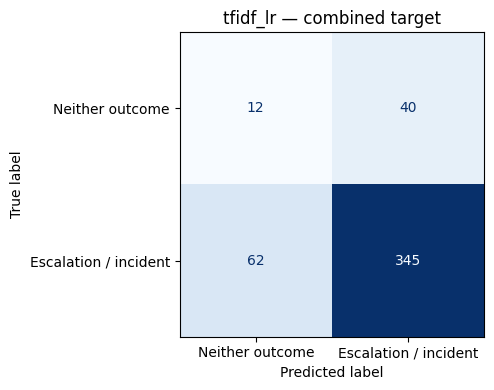

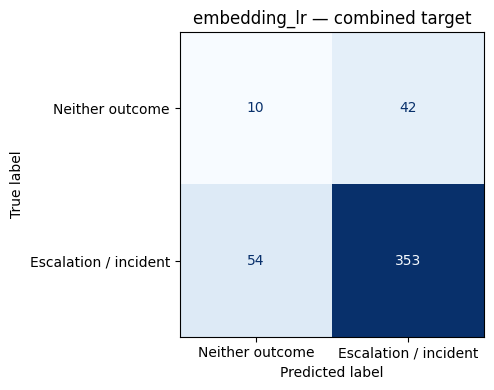

In [3]:
def evaluate(y_true,scores,t):
 pred=scores>=t;tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
 return {'precision':precision_score(y_true,pred,zero_division=0),'recall':recall_score(y_true,pred),
 'f1':f1_score(y_true,pred),'accuracy':accuracy_score(y_true,pred),'balanced_accuracy':balanced_accuracy_score(y_true,pred),
 'average_precision':average_precision_score(y_true,scores),'roc_auc':roc_auc_score(y_true,scores),
 'alert_rate':pred.mean(),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp),'threshold':float(t)}
results=[];selections=[]
for name,X in [('tfidf_lr',text_X),('embedding_lr',embed_X)]:
 models={};candidates=[]
 for C in [0.01,0.1,1.,10.,100.]:
  clf=LogisticRegression(C=C,class_weight=None,max_iter=2000,random_state=42)
  clf.fit(X['train'],y['train']);assert clf.n_iter_.max()<clf.max_iter
  ap=average_precision_score(y['validation'],clf.predict_proba(X['validation'])[:,1])
  candidates.append((ap,-C,C));models[C]=clf
 C=max(candidates)[2];clf=models[C]
 val=clf.predict_proba(X['validation'])[:,1]
 choices=[]
 for t in np.unique(np.r_[0.,val,1.]):
  pred=val>=t;r=recall_score(y['validation'],pred)
  if r>=0.90:choices.append((int(((y['validation']==0)&pred).sum()),-r,-float(t)))
 threshold=-min(choices)[2]
 selections.append({'model':name,'selected_C':C,'threshold':threshold,'validation_AP':max(candidates)[0],
                    'validation_recall':recall_score(y['validation'],val>=threshold)})
 pd.DataFrame([{'C':c,'validation_AP':ap} for ap,_,c in candidates]).to_csv(OUT/f'{name}_selection.csv',index=False)
 for part in ['validation','test']:
  score=clf.predict_proba(X[part])[:,1]
  results.append({'model':name,'partition':part,**evaluate(y[part],score,threshold)})
  d=frames[part].copy();d['risk_score']=score;d['prediction']=(score>=threshold).astype(int);d['threshold']=threshold
  d.to_csv(OUT/f'{name}_{part}_predictions.csv',index=False)
  if part=='test':
   fig,ax=plt.subplots(figsize=(5,4))
   ConfusionMatrixDisplay.from_predictions(y[part],d.prediction,display_labels=['Neither outcome','Escalation / incident'],ax=ax,colorbar=False,cmap='Blues')
   ax.set_title(name+' — combined target');fig.tight_layout();fig.savefig(OUT/f'{name}_confusion.png',dpi=150);plt.show()
 joblib.dump({'target':'escalation_or_incident_involvement','classifier':clf,'threshold':threshold,
  'vectorizer':vectorizer if name=='tfidf_lr' else None,'encoder':'sentence-transformers/all-MiniLM-L6-v2' if name=='embedding_lr' else None,
  'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text'},OUT/f'{name}_combined.joblib')
 restored=joblib.load(OUT/f'{name}_combined.joblib')
 assert np.allclose(restored['classifier'].predict_proba(X['test']),clf.predict_proba(X['test']))
results.append({'model':'always_alert','partition':'test',**evaluate(y['test'],np.full(len(y['test']),y['train'].mean()),0.)})
metrics=pd.DataFrame(results);metrics.to_csv(OUT/'combined_metrics.csv',index=False)
(OUT/'selection.json').write_text(json.dumps(selections,indent=2))
print(metrics[metrics.partition=='test'].round(4).to_string(index=False))
print('Model reload checks passed. Results concern the combined target, not escalation alone.')